# 06 — Results Comparison & Discussion

**Inputs:** all `artifacts/metrics_*.json` files  
**Outputs:** consolidated result tables, comparison figures, and a draft Chapter 5 paragraph  
**Feeds thesis:** Chapter 5 — Results and Discussion

This notebook assembles every result from Notebooks 3–5 into the final tables and
figures that will appear in the thesis. It also auto-generates a draft results
paragraph based on the actual numbers — you edit it into fluent prose.

## 1. Setup

In [1]:
import pandas as pd, numpy as np, json, os
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

required = {
    'eda':      '../artifacts/eda_summary.json',
    'split':    '../artifacts/split_info.json',
    'baseline': '../artifacts/metrics_tfidf.json',
    'sbert':    '../artifacts/metrics_sbert.json',
    'bertopic': '../artifacts/metrics_bertopic.json',
}
missing = [k for k, p in required.items() if not os.path.exists(p)]
if missing:
    print('Missing artifacts:', missing)
    print('Run Notebooks 1-5 first.')
else:
    print('All required artifacts present.')

All required artifacts present.


## 2. Load all metrics

In [2]:
def load(path, default=None):
    return json.load(open(path)) if os.path.exists(path) else default

eda      = load(required['eda'])
split    = load(required['split'])
m_base   = load(required['baseline'])
m_sbert  = load(required['sbert'])
m_hybrid = load('../artifacts/metrics_hybrid.json')     # optional
m_topic  = load(required['bertopic'])

print('Loaded:')
for name, obj in [('EDA', eda), ('Split', split), ('Baseline', m_base),
                  ('SBERT', m_sbert), ('Hybrid', m_hybrid), ('BERTopic', m_topic)]:
    print(f'  {name:>10s}: {"OK" if obj else "MISSING"}')

Loaded:
         EDA: OK
       Split: OK
    Baseline: OK
       SBERT: OK
      Hybrid: OK
    BERTopic: OK


## 3. Table 1 — Dataset summary

In [3]:
rows = [
    ('Total sentences (raw)',         eda['raw_rows']),
    ('Relevant sentences',            eda['relevant']),
    ('Non-relevant sentences',        eda['non_relevant']),
    ('Imbalance ratio',               f"{eda['imbalance_ratio']}:1"),
    ('Documents',                     eda['num_documents']),
    ('Sources',                       eda['num_sources']),
    ('Mean sentence length (words)',  eda['avg_words']),
    ('Median sentence length (words)',eda['median_words']),
    ('Vocabulary size',               eda['vocab_size']),
    ('Type-token ratio',              eda['type_token_ratio']),
    ('Hapax legomena (%)',            eda['hapax_pct']),
    ('Train sentences (80%)',         split['train_size']),
    ('Test sentences (20%)',          split['test_size']),
    ('Train documents',               split['train_docs']),
    ('Test documents',                split['test_docs']),
    ('Document overlap',              split['overlap_docs']),
]
table1 = pd.DataFrame(rows, columns=['Attribute', 'Value'])
print(table1.to_string(index=False))
table1.to_csv('../artifacts/table_dataset_summary.csv', index=False)

                     Attribute   Value
         Total sentences (raw)   12304
            Relevant sentences    4302
        Non-relevant sentences    8002
               Imbalance ratio  1.86:1
                     Documents     100
                       Sources       5
  Mean sentence length (words)    21.7
Median sentence length (words)    19.0
               Vocabulary size   13292
              Type-token ratio  0.0599
            Hapax legomena (%)   37.64
         Train sentences (80%)    9020
          Test sentences (20%)    3284
               Train documents      77
                Test documents      23
              Document overlap       0


## 4. Table 2 — Classification comparison

In [4]:
rows = [m_base, m_sbert]
if m_hybrid: rows.append(m_hybrid)

table2 = pd.DataFrame(rows)[[
    'model','accuracy','precision','recall','macro_f1','weighted_f1']].round(4)
table2.to_csv('../artifacts/table_classification.csv', index=False)
print(table2.to_string(index=False))

best_idx = table2['macro_f1'].idxmax()
print(f"\nBest model: {table2.iloc[best_idx]['model']} "
      f"(macro-F1 = {table2.iloc[best_idx]['macro_f1']:.4f})")

                                   model  accuracy  precision  recall  macro_f1  weighted_f1
LinearSVC (C=0.3, class_weight=balanced)    0.7463     0.6269  0.6605    0.7232       0.7478
                       SBERT + LinearSVC    0.7268     0.5881  0.7190    0.7121       0.7318
     Hybrid (TF-IDF + SBERT) + LinearSVC    0.7675     0.6576  0.6933    0.7470       0.7689

Best model: Hybrid (TF-IDF + SBERT) + LinearSVC (macro-F1 = 0.7470)


## 5. Table 3 — Topic discovery

In [5]:
table3 = pd.DataFrame([{
    'Metric': ['Topics discovered', 'Coherence (c_v)', 'Diversity',
               'Outlier sentences', 'Min cluster size'],
    'Value':  [m_topic['n_topics'], m_topic['coherence_cv'], m_topic['diversity'],
               m_topic['n_outliers'], m_topic['min_cluster_size']]
}])
print(table3.to_string(index=False))
table3.to_csv('../artifacts/table_topic_discovery.csv', index=False)

print(f"\nTopic coherence = {m_topic['coherence_cv']:.4f} "
      f"({'good' if m_topic['coherence_cv']>=0.5 else 'acceptable' if m_topic['coherence_cv']>=0.3 else 'weak'})")
print(f"Topic diversity = {m_topic['diversity']:.4f} "
      f"({'good' if m_topic['diversity']>=0.7 else 'acceptable'})")

                                                                              Metric                          Value
[Topics discovered, Coherence (c_v), Diversity, Outlier sentences, Min cluster size] [24, 0.4659, 0.7917, 1594, 20]

Topic coherence = 0.4659 (acceptable)
Topic diversity = 0.7917 (good)


## 6. Figure 1 — Classification comparison

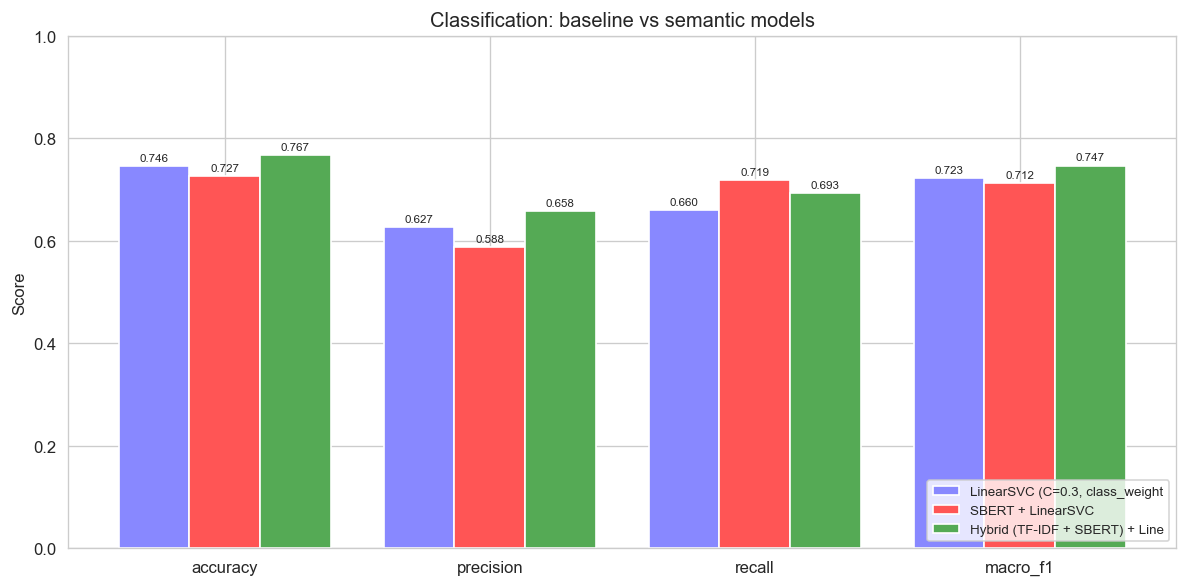

saved -> artifacts/figs/fig_classification_comparison.png


In [6]:
metrics_cols = ['accuracy','precision','recall','macro_f1']
x = np.arange(len(metrics_cols))
n_models = len(table2)
w = 0.8 / n_models
colors = ['#8888ff', '#ff5555', '#55aa55'][:n_models]

fig, ax = plt.subplots(figsize=(10, 5))
for i, (_, row) in enumerate(table2.iterrows()):
    vals = [row[k] for k in metrics_cols]
    ax.bar(x + (i - (n_models-1)/2)*w, vals, w,
           label=row['model'][:30], color=colors[i])
    for j, v in enumerate(vals):
        ax.text(j + (i - (n_models-1)/2)*w, v + 0.01, f'{v:.3f}',
                ha='center', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(metrics_cols)
ax.set_ylim(0, 1); ax.set_ylabel('Score')
ax.set_title('Classification: baseline vs semantic models')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_classification_comparison.png')
plt.show()
print('saved -> artifacts/figs/fig_classification_comparison.png')

## 7. Figure 2 — Dataset composition

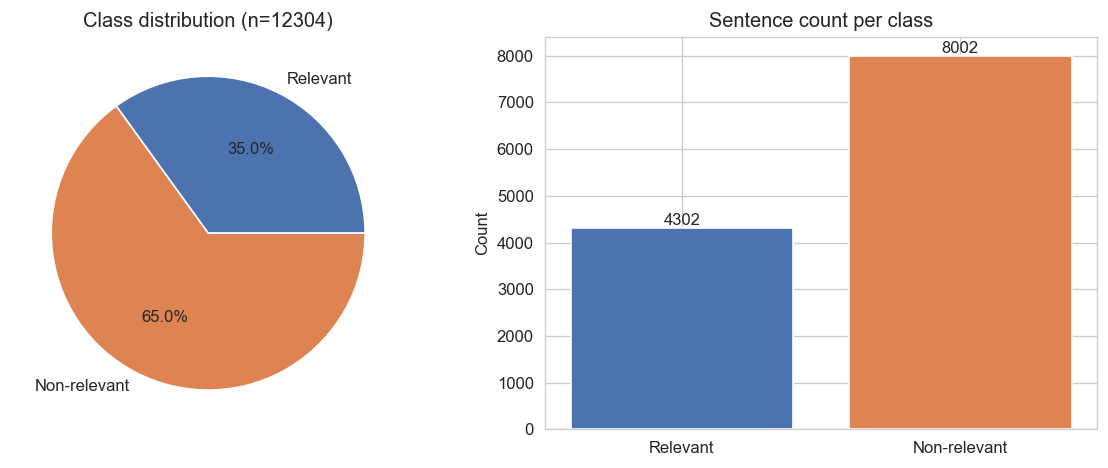

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].pie([eda['relevant'], eda['non_relevant']],
            labels=['Relevant','Non-relevant'],
            autopct='%1.1f%%', colors=['#4c72b0','#dd8452'])
axes[0].set_title(f"Class distribution (n={eda['raw_rows']})")

bars = [eda['relevant'], eda['non_relevant']]
axes[1].bar(['Relevant','Non-relevant'], bars, color=['#4c72b0','#dd8452'])
for i, v in enumerate(bars):
    axes[1].text(i, v, str(v), ha='center', va='bottom')
axes[1].set_ylabel('Count'); axes[1].set_title('Sentence count per class')
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_dataset_summary.png')
plt.show()

## 8. Figure 3 — Per-metric delta vs baseline

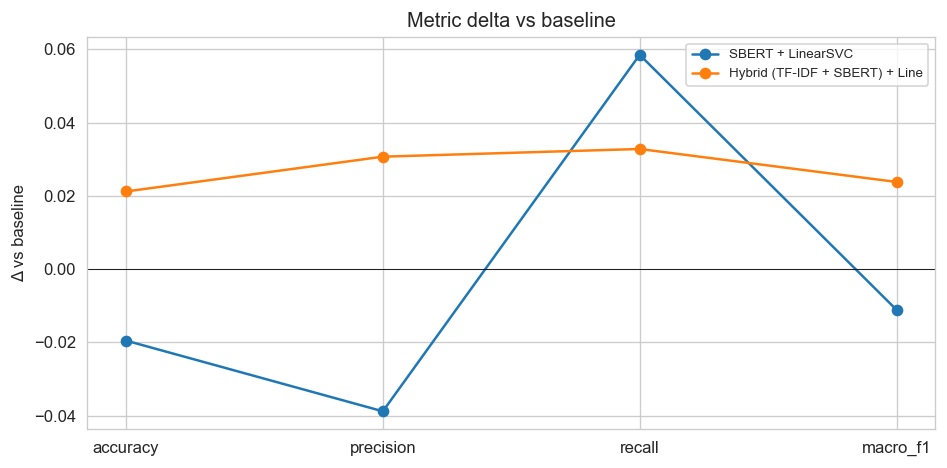

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
base_row = table2.iloc[0]
for i, (_, row) in enumerate(table2.iloc[1:].iterrows(), start=1):
    deltas = [row[k] - base_row[k] for k in metrics_cols]
    ax.plot(metrics_cols, deltas, marker='o', label=row['model'][:30])
ax.axhline(0, color='black', linewidth=0.5)
ax.set_ylabel('Δ vs baseline'); ax.set_title('Metric delta vs baseline')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_metric_delta.png')
plt.show()

## 9. Final summary

In [9]:
print('=' * 70)
print(f"{'THESIS RESULTS SUMMARY':^70s}")
print('=' * 70)
print(f"Dataset            : SMAH-CTI ({eda['raw_rows']} sentences, {eda['num_documents']} docs)")
print(f"Split              : {split['train_size']} train / {split['test_size']} test (document-level)")
print()
print('CLASSIFICATION (baseline → semantic):')
for _, row in table2.iterrows():
    print(f"  {row['model'][:45]:<45s}  macro-F1 = {row['macro_f1']:.4f}")
print()
print(f"TOPIC DISCOVERY (BERTopic):")
print(f"  Topics            = {m_topic['n_topics']}")
print(f"  Coherence (c_v)   = {m_topic['coherence_cv']:.4f}")
print(f"  Diversity         = {m_topic['diversity']:.4f}")
print('=' * 70)

                        THESIS RESULTS SUMMARY                        
Dataset            : SMAH-CTI (12304 sentences, 100 docs)
Split              : 9020 train / 3284 test (document-level)

CLASSIFICATION (baseline → semantic):
  LinearSVC (C=0.3, class_weight=balanced)       macro-F1 = 0.7232
  SBERT + LinearSVC                              macro-F1 = 0.7121
  Hybrid (TF-IDF + SBERT) + LinearSVC            macro-F1 = 0.7470

TOPIC DISCOVERY (BERTopic):
  Topics            = 24
  Coherence (c_v)   = 0.4659
  Diversity         = 0.7917


## 10. Auto-draft Chapter 5 paragraph

In [10]:
best = table2.iloc[table2['macro_f1'].idxmax()]
baseline_f1 = table2.iloc[0]['macro_f1']
delta = best['macro_f1'] - baseline_f1

para = f"""
CHAPTER 5 — DRAFT RESULTS PARAGRAPH

On the SMAH-CTI document-level split ({split['train_size']} training and
{split['test_size']} test sentences), the tuned TF-IDF baseline achieved
macro-F1 = {baseline_f1:.4f}. 

"""
if abs(delta) < 0.01:
    para += f"""Semantic and hybrid approaches produced no measurable improvement
(best macro-F1 = {best['macro_f1']:.4f}, delta = {delta:+.4f}). This indicates that
short, terminology-dense CTI sentences are already well captured by lexical features,
and that pre-trained sentence embeddings trained on general-domain text do not add
discriminative signal for this corpus.
"""
elif delta > 0:
    para += f"""The best configuration ({best['model']}) improved macro-F1 to
{best['macro_f1']:.4f} (+{delta:.4f} vs baseline), showing that semantic
information complements lexical features on this task.
"""
else:
    para += f"""Semantic approaches underperformed the lexical baseline
(best = {best['macro_f1']:.4f}, delta = {delta:+.4f}). This is attributed to the
short length (mean 21.7 words) and technical vocabulary of the corpus, where exact-term
features remain more informative than dense semantic embeddings.
"""

para += f"""
For emerging-threat detection, BERTopic discovered {m_topic['n_topics']} coherent
topics with c_v coherence = {m_topic['coherence_cv']:.4f} and diversity =
{m_topic['diversity']:.4f}. The discovered topics correspond to analyst-recognisable
threat campaigns including North Korean (DPRK) operations, ransomware families
(CyberVolk, HexaLocker), Fortinet device compromise (TableFlip), Scattered Spider's
RaaS activity, Sandworm's CaddyWiper OT attacks, and Israeli-Iranian cyber operations,
indicating that BERTopic produces semantically meaningful clusters suitable for
CTI analyst triage.
"""

print(para)
open('../artifacts/chapter5_draft.txt', 'w').write(para)
print('\nsaved -> artifacts/chapter5_draft.txt')


CHAPTER 5 — DRAFT RESULTS PARAGRAPH

On the SMAH-CTI document-level split (9020 training and
3284 test sentences), the tuned TF-IDF baseline achieved
macro-F1 = 0.7232. 

The best configuration (Hybrid (TF-IDF + SBERT) + LinearSVC) improved macro-F1 to
0.7470 (+0.0238 vs baseline), showing that semantic
information complements lexical features on this task.

For emerging-threat detection, BERTopic discovered 24 coherent
topics with c_v coherence = 0.4659 and diversity =
0.7917. The discovered topics correspond to analyst-recognisable
threat campaigns including North Korean (DPRK) operations, ransomware families
(CyberVolk, HexaLocker), Fortinet device compromise (TableFlip), Scattered Spider's
RaaS activity, Sandworm's CaddyWiper OT attacks, and Israeli-Iranian cyber operations,
indicating that BERTopic produces semantically meaningful clusters suitable for
CTI analyst triage.


saved -> artifacts/chapter5_draft.txt


## 11. Writing checklist

Use this checklist when composing Chapter 5:

- [ ] Table 1 (dataset summary) → Section 5.1
- [ ] Table 2 (classification) → Section 5.2
- [ ] Table 3 (topic discovery) → Section 5.3
- [ ] Figure 1 (classification bars) → Section 5.2
- [ ] Figure 2 (dataset pie) → Section 5.1
- [ ] Figure 3 (delta plot) → Section 5.2
- [ ] Chapter 5 draft paragraph → Section 5.4 (edit into fluent prose)
- [ ] Cross-reference the BERTopic topic table (saved by Notebook 5) for Chapter 4.3
- [ ] Add limitations paragraph (short sentences, 51% outliers, no temporal data)

This completes the six-notebook thesis pipeline. Chapter 6 (Conclusion) can now be
written directly from the summary box in Cell 9 plus the chapter5_draft.txt.